# 06 · Variance analysis

Notebook 04 ranked the five methods by sample complexity, and notebook 05 found that a baseline can increase the variance. Here we
look at the estimators themselves, at fixed policies:

1. **Exact check on a tiny poem MDP.** With two words and lines of 1-2-1 syllables there are only a few hundred possible poems, so we can
   compute $\nabla J$, and the exact mean and variance of every estimator, by enumerating all trajectories. This checks unbiasedness
   (REINFORCE, GPOMDP and both baselines, including $b_t$) with no Monte Carlo error, on the same code that is used for training. It also shows
   two estimators that look reasonable but are biased.
2. **Variance on the real poem MDP** at three fixed policies (initial, mid-training, late), for the four batch estimators and for the
   actor step of the actor-critic with a fixed critic.
3. **Relation to the sample-complexity ranking** of notebook 04, with the headline figure: sample complexity against step size.
4. **Discussion.**

In [1]:
import sys, json
from pathlib import Path
sys.path.insert(0, str(Path('..') / 'src'))

import numpy as np
import matplotlib.pyplot as plt
from poet import experiments as X, protocol as P, evaluate as ev, estimators as E, exact as Ex, train, stats, variance as Vr
from poet.estimators import LABELS
from poet.haiku import HaikuMDP, RewardConfig
from poet.policy import TabularSoftmax

plt.rcParams['figure.dpi'] = 110
COLORS = {m: f'C{k}' for k, m in enumerate(P.METHODS)}
lm = X.get_lm()

## 1. Exact check on a tiny poem MDP

The tiny MDP is the haiku MDP of notebook 03 with:
- a vocabulary of two words, *sea* (1 syllable) and *ocean* (2 syllables), with the bigram restricted to them and renormalised;
- three lines with targets **1-2-1** syllables and tolerance 0, so a line is force-ended as soon as it exceeds its target;
- the full shaped reward of notebooks 03–04, KL penalty to the bigram (η = 0.5) included.

The state is the same as in the real MDP: previous word, line, syllables so far, and whether all previous lines were exact.
For the policy we take the bigram logits plus independent $\mathcal N(0, 1)$ noise on every table entry, so that $\theta$ is a generic
point and not a special one (at $\theta_0$ the KL penalty is zero for every action).

In [2]:
tiny_lm = Ex.restrict_bigram(lm, ['sea', 'ocean'])
tiny = HaikuMDP(tiny_lm, RewardConfig(), targets=(1, 2, 1), tolerance=0)
tiny_pol = TabularSoftmax(tiny.bigram_logits(1.0), 1.0)
trajs, probs = Ex.enumerate_trajectories(tiny, tiny_pol)
index = Ex.state_index(trajs)
rng = np.random.default_rng(0)
for s in index:
    tiny_pol.row(s)[:] += rng.normal(0.0, 1.0, tiny.n_actions)
trajs, probs = Ex.enumerate_trajectories(tiny, tiny_pol)        # again, under the perturbed policy
nA, T = tiny.n_actions, tiny.horizon
def is_valid(env, actions):
    s = env.reset()
    for a in actions:
        s, info = env.transition(s, a)
    return info['poem_valid']
p_valid = sum(p for tr, p in zip(trajs, probs) if is_valid(tiny, tr.actions))
print(f'{len(trajs)} possible poems, {len(index)} reachable states, {len(index) * nA} parameters, horizon T = {T}')
print(f'sum of probabilities = {probs.sum():.12f}, P(valid 1-2-1) = {p_valid:.3f}, J(theta) = {probs @ [tr.ret for tr in trajs]:.4f}')
print('most likely poems:')
for k in np.argsort(-probs)[:5]:
    print(f'  p = {probs[k]:.3f}  R = {trajs[k].ret:6.2f}  {tiny.format_poem(trajs[k].actions)}')

225 possible poems, 14 reachable states, 42 parameters, horizon T = 7
sum of probabilities = 1.000000000000, P(valid 1-2-1) = 0.088, J(theta) = 6.9813
most likely poems:
  p = 0.310  R =   8.86  sea (1) / sea (1) / sea (1)
  p = 0.200  R =   3.74  sea (1) / sea (1) / ocean (2)
  p = 0.114  R =   4.02  ocean (2) / sea (1) / sea (1)
  p = 0.088  R =  23.14  sea (1) / ocean (2) / sea (1)
  p = 0.073  R =  -1.10  ocean (2) / sea (1) / ocean (2)


**Ground truth.** We compute $\nabla J(\theta)$ by central finite differences of the exact $J$, one table entry at a time. This uses no
policy gradient theorem, and it differentiates *everything*, including $\log\pi_\theta$ inside the KL penalty. We compare it with the
right-hand side of the finite-horizon policy gradient theorem, $\mathbb E[(\sum_t\nabla\log\pi(A_t|S_t))\,R(\tau)]$,
summed exactly over all poems, where $R$ is computed with the KL penalty held *fixed*, as the training code does.

They should agree. Differentiating the penalty $-\eta\log\pi_\theta(A_t|S_t)$ inside the reward adds
$-\eta\,\mathbb E[\sum_t\nabla\log\pi_\theta(A_t|S_t)]$, which is zero because the score has zero mean given the state.

In [3]:
fd = Ex.finite_difference_gradient(tiny, tiny_pol, index)
pg = sum(p * Ex.flatten(E.reinforce([tr], 1.0), index, nA) for tr, p in zip(trajs, probs))
print(f'||grad J|| (finite differences) = {np.linalg.norm(fd):.4f}')
print(f'relative difference to the policy gradient theorem (KL held fixed): {np.linalg.norm(pg - fd) / np.linalg.norm(fd):.1e}')

||grad J|| (finite differences) = 2.8808
relative difference to the policy gradient theorem (KL held fixed): 1.2e-10


**Every estimator, every batch.** Batch estimators with a leave-one-out baseline need $n \ge 2$, so we use $n = 2$. We loop over all
$N^2$ ordered pairs of poems $(\tau_i, \tau_j)$, weight each by $p_ip_j$, and call the estimator on the batch $[\tau_i, \tau_j]$. This gives
the exact mean $\mathbb E[\hat g]$ and the exact total variance $\operatorname{tr}\operatorname{Cov}[\hat g]$. The four training
estimators are the functions in `poet.estimators` used in notebooks 04–05. We also include:

- **REINFORCE, same-batch average baseline**: $b = \frac1n\sum_j R(\tau_j)$ *including* $\tau_i$, the form usually written, which
  is slightly biased. Expected: $\mathbb E[\hat g] = (1 - 1/n)\nabla J$, a relative bias of exactly $1/n = 0.5$.
- **GPOMDP + $b_t$, truncated**: the same leave-one-out $b_t$, but each episode's sum over $t$ stops at its own length instead of the
  common horizon $T$. Whether step $t$ exists depends on earlier actions, so the dropped terms $-b_t$ do not average to zero.
- **TD advantage** $\sum_h\nabla\log\pi(A_h|S_h)\,(r_h + V(S_{h+1}) - V(S_h))$, the actor step of the actor-critic with a fixed critic $V$:
  with the exact $V^\pi$ (computed by recursion over the acyclic MDP), with $V^\pi$ plus $\mathcal N(0,1)$ noise per state, and with
  $V \equiv 0$ (each action credited with its immediate reward only).

In [4]:
V_exact = Ex.value_function(tiny, tiny_pol)
print(f'V^pi(s_0) = {V_exact[tiny.reset()]:.4f}  (= J, as it should)')
rng = np.random.default_rng(1)
V_noisy = {s: v + rng.normal(0.0, 1.0) for s, v in V_exact.items()}
candidates = {
    'REINFORCE':                          lambda b: E.estimate('reinforce', b, 1.0, T),
    'REINFORCE + b (leave-one-out)':      lambda b: E.estimate('reinforce_b', b, 1.0, T),
    'GPOMDP':                             lambda b: E.estimate('gpomdp', b, 1.0, T),
    'GPOMDP + b_t (leave-one-out, to T)': lambda b: E.estimate('gpomdp_b', b, 1.0, T),
    'REINFORCE + same-batch average b':   lambda b: Ex.reinforce_same_batch_baseline(b, 1.0),
    'GPOMDP + b_t truncated at L_i':      lambda b: Ex.gpomdp_truncated_baseline(b, 1.0),
    'TD advantage, V = V^pi':             lambda b: E.td_advantage(b, 1.0, V_exact),
    'TD advantage, V = V^pi + noise':     lambda b: E.td_advantage(b, 1.0, V_noisy),
    'TD advantage, V = 0':                lambda b: E.td_advantage(b, 1.0, {}),
}
exact = {name: Ex.pair_moments(f, trajs, probs, index, nA) for name, f in candidates.items()}
ref = exact['REINFORCE'][1]
print(f'\n{"estimator (n = 2)":38s} {"relative bias":>14s} {"tr Cov":>9s} {"vs REINFORCE":>13s}')
for name, (mean, var) in exact.items():
    bias = np.linalg.norm(mean - fd) / np.linalg.norm(fd)
    print(f'{name:38s} {bias:14.1e} {var:9.3f} {var / ref:12.2f}x')
print('relative bias = ||E[g] - grad J|| / ||grad J||, with grad J from finite differences')

V^pi(s_0) = 6.9813  (= J, as it should)



estimator (n = 2)                       relative bias    tr Cov  vs REINFORCE
REINFORCE                                     1.2e-10    53.960         1.00x
REINFORCE + b (leave-one-out)                 1.2e-10    53.600         0.99x
GPOMDP                                        1.2e-10    34.109         0.63x
GPOMDP + b_t (leave-one-out, to T)            1.2e-10    43.162         0.80x
REINFORCE + same-batch average b              5.0e-01    13.400         0.25x
GPOMDP + b_t truncated at L_i                 2.2e-01    25.591         0.47x
TD advantage, V = V^pi                        1.2e-10    11.861         0.22x
TD advantage, V = V^pi + noise                1.4e-01    11.608         0.22x
TD advantage, V = 0                           7.5e-01     0.958         0.02x
relative bias = ||E[g] - grad J|| / ||grad J||, with grad J from finite differences


The relative bias of the unbiased estimators is about $10^{-10}$, which is the finite-difference error of the reference gradient. Next we
move to the real MDP, where nothing can be enumerated and the variance has to be estimated.

## 2. Variance on the real poem MDP at fixed policies

We take three snapshots of one training run with the tuned setting of notebook 04 (shaped reward, GPOMDP + $b_t$, α = 3, batch 10):
- $\theta_0$: the bigram (0 episodes);
- $\theta_{\text{mid}}$: after 2 000 episodes, when the return has risen substantially but almost no poem is valid yet;
- $\theta_{\text{late}}$: after 3 500 episodes, when the valid rate has jumped and the policy starts to collapse (about where the policy of notebook 05 was).

In [5]:
env = X.make_env({})
pol = X.make_policy(env, {})
rng = np.random.default_rng(0)
snapshots, done = {}, 0
for name, episodes in [('theta_0', 0), ('theta_mid', 2000), ('theta_late', 3500)]:
    while done < episodes:
        train.train_batch_pg(env, pol, 'gpomdp_b', 3.0, 10, 500, rng)
        done += 500
    snapshots[name] = pol.copy()
    m = ev.poem_metrics(env, ev.sample_poems(env, pol, 1000, np.random.default_rng(1)))
    print(f"{name:10s} after {episodes:4d} episodes: return {m['return']:5.1f}, valid {m['valid']:.2f}, "
          f"distinct poems {m['distinct_poems']:.2f}, vocabulary used {m['distinct_words']:.2f}, mean syllable error {m['syl_error']:.2f}")

theta_0    after    0 episodes: return   4.3, valid 0.00, distinct poems 1.00, vocabulary used 1.00, mean syllable error 2.79


theta_mid  after 2000 episodes: return  14.0, valid 0.03, distinct poems 1.00, vocabulary used 1.00, mean syllable error 1.42


theta_late after 3500 episodes: return  29.0, valid 0.72, distinct poems 0.34, vocabulary used 0.93, mean syllable error 0.36


At each snapshot we draw $M = 1000$ independent batches of $n = 10$ episodes and compute every estimator on the same batches. For each one
we report:
- the total variance $\operatorname{tr}\operatorname{Cov}[\hat g]$ with its standard error (from a second pass over the same batches);
- $\widehat{\|\nabla J\|^2} = \|\bar g\|^2 - \operatorname{tr}\operatorname{Cov}/M$, an unbiased estimate of $\|\mathbb E\hat g\|^2$. For
  the four unbiased estimators this is the same number $\|\nabla J\|^2$, so their four estimates should agree up to noise.

**The actor-critic.** Its update is per step and its critic changes during training, so there is no single "AC estimator" at a fixed
policy. As a stand-in we use the TD-advantage batch estimator above. The critic $\hat V$ is fitted by Monte Carlo on 20 000 separate
episodes at the same policy (a best case for the actor-critic's TD(0) critic). $\hat V$ is not exact, so this estimator is biased.
To measure the bias we also treat the difference "TD advantage − GPOMDP + $b_t$" as an estimator: its $\widehat{\|\cdot\|^2}$ is an
unbiased estimate of $\|\text{bias}\|^2$.

In [6]:
M, N_BATCH = 1000, 10
var = {}
for name, theta in snapshots.items():
    V_hat = Vr.fit_critic_mc(env, theta, 20_000, np.random.default_rng(2))
    td = lambda b, V=V_hat, th=theta: E.td_advantage(b, th.tau, V)
    def td_minus_ref(b, V=V_hat, th=theta):
        g = dict(E.td_advantage(b, th.tau, V))
        for s, row in E.estimate('gpomdp_b', b, th.tau, env.horizon).items():
            g[s] = g[s] - row if s in g else -row
        return g
    var[name] = Vr.estimator_variance(env, theta, E.METHODS, N_BATCH, M, np.random.default_rng(3),
                                      extra={'td': td, 'td_bias': td_minus_ref})
    print(f'\n{name}  ({len(V_hat)} states in the fitted critic)')
    print(f'{"estimator":24s} {"tr Cov":>16s} {"vs REINFORCE":>13s} {"||grad J||^2 est.":>18s}')
    for m in E.METHODS + ['td']:
        v = var[name][m]
        label = LABELS[m] if m in LABELS else 'TD advantage, MC critic'
        print(f"{label:24s} {v['total_var']:8.2f} ± {v['total_var_se']:5.2f} {v['total_var'] / var[name]['reinforce']['total_var']:12.2f}x {v['grad_sq']:18.3f}")
    b = var[name]['td_bias']
    g2 = var[name]['gpomdp_b']['grad_sq']
    print(f"bias of the TD advantage: ||bias||^2 = {b['grad_sq']:.4f}, ||grad J||^2 (GPOMDP + b_t) = {g2:.4f}"
          f"  ->  ||bias|| / ||grad J|| = {np.sqrt(max(b['grad_sq'], 0) / g2):.2f}")


theta_0  (13222 states in the fitted critic)
estimator                          tr Cov  vs REINFORCE  ||grad J||^2 est.
REINFORCE                   54.64 ±  0.79         1.00x              0.001
REINFORCE + baseline        23.49 ±  0.45         0.43x              0.001
GPOMDP                      23.45 ±  0.31         0.43x              0.002
GPOMDP + baseline b_t       18.30 ±  0.28         0.33x              0.002
TD advantage, MC critic      1.80 ±  0.02         0.03x              0.004
bias of the TD advantage: ||bias||^2 = 0.0019, ||grad J||^2 (GPOMDP + b_t) = 0.0021  ->  ||bias|| / ||grad J|| = 0.95



theta_mid  (15195 states in the fitted critic)
estimator                          tr Cov  vs REINFORCE  ||grad J||^2 est.
REINFORCE                   34.98 ±  0.45         1.00x              1.856
REINFORCE + baseline        28.43 ±  0.52         0.81x              1.821
GPOMDP                      13.30 ±  0.26         0.38x              1.875
GPOMDP + baseline b_t       14.73 ±  0.30         0.42x              1.859
TD advantage, MC critic      4.43 ±  0.06         0.13x              1.920
bias of the TD advantage: ||bias||^2 = 0.0051, ||grad J||^2 (GPOMDP + b_t) = 1.8585  ->  ||bias|| / ||grad J|| = 0.05



theta_late  (9699 states in the fitted critic)
estimator                          tr Cov  vs REINFORCE  ||grad J||^2 est.
REINFORCE                    7.91 ±  0.25         1.00x              0.070
REINFORCE + baseline         8.65 ±  0.21         1.09x              0.076
GPOMDP                       6.73 ±  0.20         0.85x              0.068
GPOMDP + baseline b_t       13.03 ±  0.22         1.65x              0.076
TD advantage, MC critic      2.84 ±  0.07         0.36x              0.073
bias of the TD advantage: ||bias||^2 = 0.0026, ||grad J||^2 (GPOMDP + b_t) = 0.0757  ->  ||bias|| / ||grad J|| = 0.19


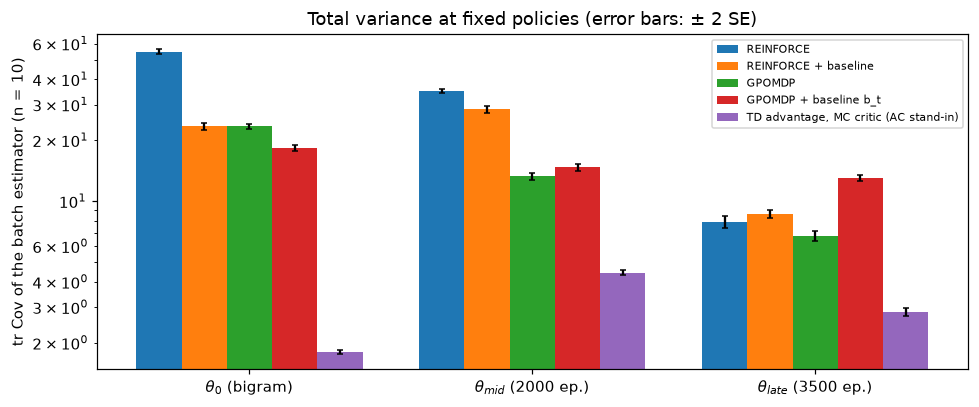

In [7]:
names = list(snapshots)
est = E.METHODS + ['td']
fig, ax = plt.subplots(figsize=(9, 3.8))
w = 0.16
for k, m in enumerate(est):
    y = [var[n][m]['total_var'] for n in names]
    e = [2 * var[n][m]['total_var_se'] for n in names]
    ax.bar(np.arange(3) + (k - 2) * w, y, w, yerr=e, capsize=2, color=COLORS.get(m, 'C4'),
           label=LABELS[m] if m in LABELS else 'TD advantage, MC critic (AC stand-in)')
ax.set_xticks(range(3)); ax.set_xticklabels([r'$\theta_0$ (bigram)', r'$\theta_{mid}$ (2000 ep.)', r'$\theta_{late}$ (3500 ep.)'])
ax.set_ylabel('tr Cov of the batch estimator (n = 10)'); ax.set_yscale('log')
ax.set_title('Total variance at fixed policies (error bars: ± 2 SE)'); ax.legend(fontsize=7)
plt.tight_layout(); plt.show()

## 3. Relation to the sample-complexity ranking

Notebook 04 tuned α separately for each method and measured the sample complexity at the tuned α. A standard smoothness argument
tells us what variance should predict. Suppose $J$ is $L$-smooth and $\hat g$ is unbiased with total variance $\sigma^2$.
Then one step $\theta' = \theta + \alpha\hat g$ improves $J$ in expectation by at least
$$\alpha\|\nabla J\|^2 - \tfrac{L\alpha^2}{2}\left(\|\nabla J\|^2 + \sigma^2\right).$$
For a small enough step, any variance is harmless. Variance limits how *large* a step can be taken before the noise term wins, and the
step size where the bound stops guaranteeing progress scales like $\|\nabla J\|^2/\sigma^2$. So lower variance should show up as
tolerance of larger step sizes, and as faster learning only when the step size is chosen near that limit.

**Headline figure: sample complexity against step size.** For every method and every α of notebook 04's grid, we plot the sample
complexity (return ≥ 30) of the 3 tuning runs. The marker is at the mean over the runs that reached the target, the label gives how many
did, and a cross at the top marks an α where no run did. The actor-critic is plotted at 10α, its batch-equivalent step size (it updates
after every episode, a batch method once per 10 episodes; see the discussion). After the figure, a table puts the variance ratios of §2
next to notebook 04's final sample complexities and tuning profile.

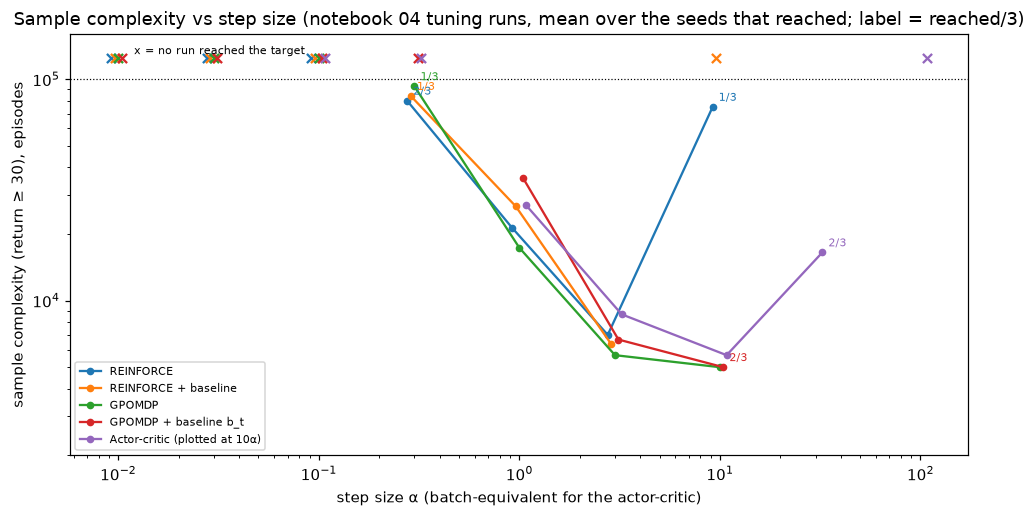

In [8]:
target = json.load(open(X.RESULTS_DIR / '04_target.json'))
best04 = {'reinforce': 3.0, 'reinforce_b': 3.0, 'gpomdp': 3.0, 'gpomdp_b': 3.0, 'ac': 1.0}
final04 = X.run_many([P.spec(m, best04[m], s) for m in P.METHODS for s in P.FINAL_SEEDS], X.RESULTS_DIR / '04_final.pkl', verbose=False)
grid04 = [0.01, 0.03, 0.1, 0.3, 1.0, 3.0, 10.0]
tuning04 = X.run_many([P.spec(m, a, s) for m in P.METHODS for a in grid04 for s in P.TUNE_SEEDS], X.RESULTS_DIR / '04_tuning.pkl', verbose=False)
score, sc_tune = {}, {}
for sp, r in zip([P.spec(m, a, s) for m in P.METHODS for a in grid04 for s in P.TUNE_SEEDS], tuning04):
    score.setdefault((sp['method'], sp['alpha']), []).append(P.tuning_score(r))
    sc_tune.setdefault((sp['method'], sp['alpha']), []).append(P.sample_complexity(r['history'], target['return_target']))

fig, ax = plt.subplots(figsize=(9, 4.8))
for m in P.METHODS:
    scale = 10 if m == 'ac' else 1
    xs_, ys_ = [], []
    for a in grid04:
        hit = [v for v in sc_tune[(m, a)] if v is not None]
        x = a * scale * (1 + 0.04 * (P.METHODS.index(m) - 2))          # small horizontal offset per method
        if hit:
            xs_.append(x); ys_.append(np.mean(hit))
            if len(hit) < len(P.TUNE_SEEDS):
                ax.annotate(f'{len(hit)}/{len(P.TUNE_SEEDS)}', (x, np.mean(hit)), textcoords='offset points', xytext=(4, 4),
                            fontsize=7, color=COLORS[m])
        else:
            ax.scatter(x, 1.25 * P.N_EPISODES, marker='x', color=COLORS[m])
    label = LABELS[m] + (' (plotted at 10α)' if m == 'ac' else '')
    ax.plot(xs_, ys_, 'o-', color=COLORS[m], label=label, ms=4)
ax.axhline(P.N_EPISODES, color='k', lw=0.8, ls=':')
ax.text(0.012, 1.3 * P.N_EPISODES, 'x = no run reached the target', fontsize=7)
ax.set_xscale('log'); ax.set_yscale('log'); ax.set_ylim(2000, 1.6 * P.N_EPISODES)
ax.set_xlabel('step size α (batch-equivalent for the actor-critic)'); ax.set_ylabel('sample complexity (return ≥ 30), episodes')
ax.set_title("Sample complexity vs step size (notebook 04 tuning runs, mean over the seeds that reached; label = reached/3)")
ax.legend(fontsize=7, loc='lower left')
plt.tight_layout(); plt.show()

In [9]:
print(f'{"":24s} {"variance vs REINFORCE":>27s}   {"notebook 04":>40s}')
print(f'{"method":24s} {"theta_0":>8s} {"mid":>8s} {"late":>8s}   {"SC (return >= 30)":>20s}' + ''.join(f'{"a=" + str(a):>8s}' for a in [0.3, 1.0, 3.0, 10.0]))
for k, m in enumerate(P.METHODS):
    key = m if m != 'ac' else 'td'
    rel = [var[n][key]['total_var'] / var[n]['reinforce']['total_var'] for n in names]
    sc = [P.sample_complexity(r['history'], target['return_target']) for r in final04[k * 10:(k + 1) * 10]]
    mean, hw = stats.mean_ci(sc)
    print(f'{LABELS[m]:24s}' + ''.join(f'{x:8.2f}' for x in rel) + f'   {mean:10,.0f} ± {hw:5,.0f} (a={best04[m]:g})'
          + ''.join(f'{np.mean(score[(m, a)]):8.1f}' for a in [0.3, 1.0, 3.0, 10.0]))
print('variance for the actor-critic = TD-advantage stand-in; tuning columns = mean evaluation return over the budget (3 seeds)')

                               variance vs REINFORCE                                notebook 04
method                    theta_0      mid     late      SC (return >= 30)   a=0.3   a=1.0   a=3.0  a=10.0
REINFORCE                   1.00    1.00    1.00        6,500 ±   695 (a=3)    14.8    30.0    33.3     9.6
REINFORCE + baseline        0.43    0.81    1.09        7,000 ±   826 (a=3)    12.8    28.7    33.7    15.1
GPOMDP                      0.43    0.38    0.85        6,200 ±   657 (a=3)    12.0    31.1    33.8    33.8
GPOMDP + baseline b_t       0.33    0.42    1.65        6,700 ±   483 (a=3)    11.0    27.0    33.7    29.3
Actor-critic                0.03    0.13    0.36        6,000 ±   477 (a=1)    33.2    33.9    15.5    13.2
variance for the actor-critic = TD-advantage stand-in; tuning columns = mean evaluation return over the budget (3 seeds)


## 4. Discussion

**Unbiasedness, exactly.** On the tiny poem MDP the four training estimators match the finite-difference gradient to a relative error of
$1.2\cdot10^{-10}$. That is the error of the finite differences themselves, so their bias is zero up to rounding. This holds for the code
used in training, with the KL penalty inside the reward. Treating that penalty as a constant is exact, not an approximation, because the
term it drops has zero mean. Two details of the implementation matter:
- The baseline must not depend on the episode it is subtracted from. The usual same-batch average baseline gives exactly
  $(1-1/n)\nabla J$: a 50% bias at $n = 2$, 10% at our $n = 10$. Our leave-one-out version is unbiased.
- The time-dependent baseline $b_t$ must be summed to the common horizon $T$. Stopping each episode's sum at its own length
  gives a 22% bias here. Our episodes have variable length (a line ends when the agent chooses), so this is a real trap and not a
  technicality.

Both biased variants have *lower* variance than the correct ones (0.25× and 0.47× REINFORCE), so a variance comparison alone would
prefer them. The same trade-off appears for the critic: the TD advantage with the exact $V^\pi$ is unbiased at 0.22× the variance, but
with noise of σ = 1 in $V$ it is 14% biased, and with $V = 0$ it is 75% biased.

**Which estimator has the lowest variance depends on the policy.**

| policy | ranking (total variance, batch of 10) |
|---|---|
| $\theta_0$, the bigram | REINFORCE (1.00) > REINFORCE + b (0.43) ≈ GPOMDP (0.43) > GPOMDP + $b_t$ (0.33): the textbook order |
| $\theta_{\text{mid}}$ | REINFORCE (1.00) > REINFORCE + b (0.81) > GPOMDP + $b_t$ (0.42) ≈ GPOMDP (0.38) |
| $\theta_{\text{late}}$ | GPOMDP + $b_t$ (1.65) > REINFORCE + b (1.09) > REINFORCE (1.00) > GPOMDP (0.85) |

- Dropping past rewards (GPOMDP) always helped, by 15–62%.
- The baselines helped a lot at the start (REINFORCE 1.00 → 0.43, GPOMDP 0.43 → 0.33). At $\theta_{\text{mid}}$ they helped
  REINFORCE less and GPOMDP not at all (0.38 → 0.42), and at the late policy they *hurt* both. This is the effect found in notebook 05: once
  the policy has learned some poems, the valid poems have small scores and the invalid ones large scores. A constant baseline then adds
  noise to the invalid episodes instead of removing it.
- On the tiny MDP with $n = 2$ the leave-one-out baseline barely helps (0.99×), because "the other episode's return" is itself a very
  noisy baseline.

**The critic is the biggest variance reduction, but it brings bias.** The TD-advantage stand-in for the actor-critic has 3%, 13% and
36% of REINFORCE's variance at the three policies. Its critic is fitted by Monte Carlo on 20 000 episodes, a best case for the TD(0)
critic, yet it is biased:
- at $\theta_{\text{mid}}$ the bias is about 5% of $\|\nabla J\|$;
- at $\theta_{\text{late}}$ it is about 20%;
- at $\theta_0$ it is as large as the gradient itself. There, however, $\|\nabla J\|^2 \approx 0.002$ is close to what 1000 batches can
  resolve (the four unbiased estimators give 0.001–0.002).

Most states (previous word, syllable count) are visited only a few times, so the critic is poor exactly where the policy is still
exploring.

**The gradient is tiny compared with the noise.** At $\theta_0$, $\operatorname{tr}\operatorname{Cov}/\|\nabla J\|^2$ is of order
$10^4$ even for the best batch estimator. At $\theta_{\text{mid}}$ it is about 7 (GPOMDP: 13.3 / 1.86). A single batch gradient is
almost all noise at the start. Learning still happens because the noise is spread over thousands of table entries and averages out
across steps, while the signal accumulates.

**Relation to the sample-complexity ranking (notebook 04).** At the tuned step size α = 3, the four batch methods reach the return
target at 6 200–7 000 episodes with overlapping confidence intervals. The 2–3× variance differences at $\theta_0$ and $\theta_{\text{mid}}$
do **not** produce a sample-complexity ranking. This is what the smoothness argument of §3 predicts: variance limits how large a step
can be taken, so it shows up in the tuning profile rather than at a well-chosen α.

The headline figure of §3 shows this directly. For every batch method the sample complexity falls steeply with α (17 000–36 000
episodes at α = 1, 6 000–7 000 at α = 3), and the curves lie on top of each other. They separate only at the large-step end. At α = 10:
- GPOMDP reaches the target in 3/3 tuning runs and GPOMDP + $b_t$ in 2/3, both after about 5 000 episodes;
- REINFORCE reaches it in 1/3 (75 000) and REINFORCE + b in none.

The methods differ in *where the curve turns back up*, not in its minimum.
- At α = 10, the two GPOMDP estimators (the lowest variance in the first half of training) still reach a mean return of 33.8 and 29.3.
  REINFORCE collapses to 9.6, and REINFORCE + b reaches 15.1.
- At α ≤ 1 the methods without a baseline are slightly *faster*. This looks like the opposite of the variance ranking, but it is still a
  **noise effect**. All four estimators are unbiased, so their mean update is the same. What differs is the noise: without a baseline the
  returns are mostly positive, so the noise pushes up *every sampled action*. This drift lowers the entropy and commits the policy to the
  poems it already writes. At moderate step sizes that helps to reach a "write any valid poem" target; at large ones it causes collapse
  (notebook 04, §4). So the *direction* of the noise matters as well as its size, and a single number like the total variance cannot
  capture that.

**The actor-critic fits the same picture once step sizes are put on a common scale.** A batch method moves $\alpha\cdot\frac1n\sum_i g_i$
once per $n = 10$ episodes, while the actor-critic moves $\alpha\cdot g_i$ (spread over the steps) after every episode. So its α
corresponds to a batch α ten times larger. Its tuned α = 1 is therefore comparable to the batch α = 10, where only the low-variance
GPOMDP estimators still work, and there the actor-critic matches the best of them (33.9, against 33.8 for GPOMDP). At α = 3 (batch-equivalent 30, beyond notebook 04's grid) it drops to 15.5.
The AC's much lower variance buys it a larger usable step, at the price of the bias measured above. Notebook 05 showed the other side of the
critic: with sparse rewards it learns too slowly to help.

**Summary.** All the unbiased estimators really are unbiased, including on our variable-length episodes and with the KL penalty, and the
two tempting shortcuts are not. Variance reduction is policy-dependent: GPOMDP's is robust, while the constant baselines help early and
hurt late. In this problem lower variance mainly widens the range of usable step sizes. It does not change the sample complexity at the
tuned step size, which is why notebook 04 found a tie.